Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Edited by:
Darío Julián Echeverría Castro

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [11]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.
print("Dataframe dimensions:", df.shape)
print("\nDataframe data types:")
print(df.info())
print("\nDescriptive statistics numerical variables:")
print(df.describe(include='number').T)
print("\nDescriptive statistics categorical variables:")
print(df.describe(include='object').T)
print("\nMissing values:")
print(df.isnull().sum())

Dataframe dimensions: (891, 12)

Dataframe data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Descriptive statistics numerical variables:
             count        mean         std   min       25%       50%    75%  \
PassengerId  891.0  446.000000  257.353842  1.00  223.5000  

**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

- Missing values:
    - 177 entries have no age value,
    - 687 entries have no cabin recorded for the passenger, and
    - 2 entries have no port of embarkation.

No treatment of the NAs will be required, since none of the hypotheses involve these variables. 

- **Further analysis:** 
    - The 177 missing age values could be imputed with the median by sex or with random sampling.
    - "PassengerId" should not be used for modeling, since it is an identifier.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

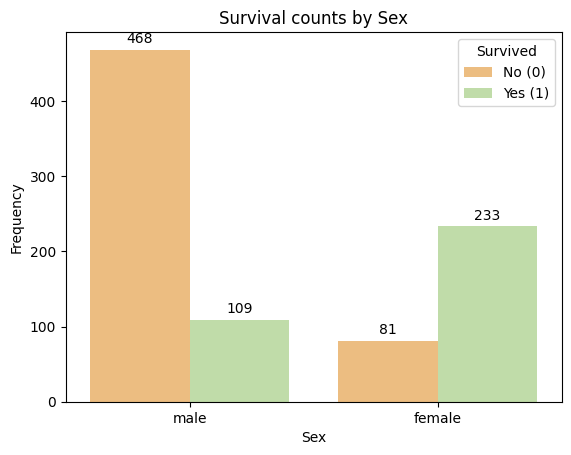

In [21]:
# Calculate survival rates by sex and visualize the comparison.
import matplotlib.pyplot as plt
import seaborn as sns

ax = sns.countplot(x = "Sex", hue = "Survived", data = df, palette = "Spectral")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_title("Survival counts by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Frequency")
ax.legend(title="Survived", labels=["No (0)", "Yes (1)"])

plt.show()

In [16]:
pd.crosstab(df["Sex"], df["Survived"], normalize="index").mul(100).round(1)

Survived,0,1
Sex,,
female,25.8,74.2
male,81.1,18.9


**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

The survival rate for females was **74.2%** (for the provided entries), 55.3 pp higher than that of males.

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

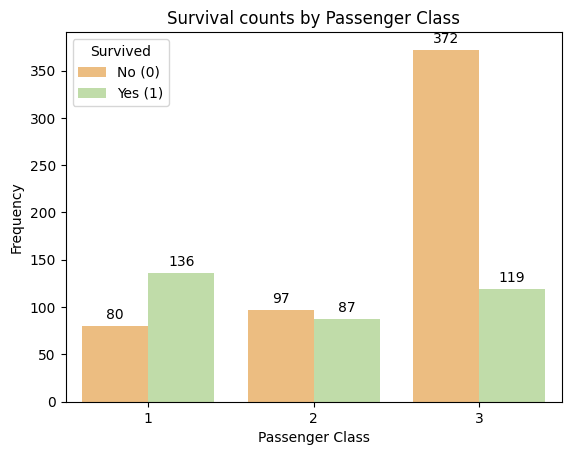

In [22]:
# Calculate survival rates by passenger class and visualize the comparison.
ax = sns.countplot(x = "Pclass", hue = "Survived", data = df, palette = "Spectral")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

ax.set_title("Survival counts by Passenger Class")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Frequency")
ax.legend(title="Survived", labels=["No (0)", "Yes (1)"])

plt.show()

In [23]:
pd.crosstab(df["Pclass"], df["Survived"], normalize="index").mul(100).round(1)

Survived,0,1
Pclass,,
1,37.0,63.0
2,52.7,47.3
3,75.8,24.2


**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

First Class had the highest survival rate at **63%**, while Third Class had the lowest, at 24.2%.
However, the counts of survivors for First Class and Third Class are similar and represent 15.3% and 13.4% of all entries, respectively.

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>